# Driver Drowsiness Detection — Complete Training Notebook
## Three independent MobileNetV2 binary classifiers

This notebook trains three separate image classifiers:

1. **Driver state:** `active` vs `fatigue`
2. **Eye state:** `open` vs `closed`
3. **Mouth state:** `no_yawn` vs `yawn`

Each model is binary and independent. A driver can have open eyes and yawn at the same time, so these are not mutually exclusive classes.

### What this notebook does
- Checks the dataset folders and counts images.
- Creates stratified train / validation / test splits (70% / 15% / 15%).
- Displays example images.
- Builds TensorFlow input pipelines and training-time augmentation.
- Uses ImageNet-pretrained MobileNetV2.
- Trains a classification head, then fine-tunes selected backbone layers.
- Evaluates each model using precision, recall, F1, confusion matrix and ROC-AUC.
- Selects thresholds using validation data only.
- Saves three `.keras` models and an inference configuration.

> **Important:** this is an educational research prototype, not a validated driver-safety system. A still image cannot reliably establish fatigue. Do not use these models to decide whether it is safe to drive or to control a vehicle. Real deployment requires independent subject/session-level validation, human-factors testing and fail-safe design.

### Before running
1. Make sure the dataset folders match the configuration in Section 3.
2. Eye images should be eye crops; mouth images should be mouth crops.
3. If images come from videos or multiple frames of the same person, split by person/video/session instead of randomly splitting individual frames. Random frame splitting can cause data leakage.
4. Run cells from top to bottom.

## 1. Expected dataset structure

The recommended structure is:

```text
Driver_Drowsiness_Dataset/
├── state/
│   ├── active/
│   └── fatigue/
├── eyes/
│   ├── open/
│   └── closed/
└── mouth/
    ├── no_yawn/
    └── yawn/
```

Each class folder should contain images (subfolders are also searched). You can change the paths and folder names in Section 3. The three task directories do not have to share the same parent.

## 2. Install and import libraries

TensorFlow is often already installed in Colab and Kaggle. If imports fail, uncomment the installation line and run it, then restart the kernel.

In [1]:
# If needed, uncomment and run:
# %pip install -q tensorflow scikit-learn matplotlib pandas pillow

import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    precision_recall_fscore_support
)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 3. Configuration — EDIT THIS CELL

Set the three task directories and exact class-folder names. The `classes` order defines the labels: class at index `0` becomes label 0 and class at index `1` becomes label 1. The positive class is therefore always the second class.

In [2]:
# Your actual Kaggle dataset structure has all six class folders directly
# inside this train directory. Do not add state/, eyes/ or mouth/ here.
DATA_ROOT = Path(
    "/kaggle/input/datasets/mohamedamineram/"
    "fatigedetection2/FatigeDetection2/train"
)

DATASETS = {
    "driver_state": {
        "directory": DATA_ROOT,
        "classes": ["Active Subjects", "Fatigue Subjects"],
        "positive_class": "Fatigue Subjects",
    },
    "eye_state": {
        "directory": DATA_ROOT,
        "classes": ["Open", "Closed"],
        "positive_class": "Closed",
    },
    "mouth_state": {
        "directory": DATA_ROOT,
        "classes": ["no_yawn", "yawn"],
        "positive_class": "yawn",
    },
}

IMAGE_SIZE = (160, 160)
BATCH_SIZE = 32
SEED = 42

TRAIN_FRACTION = 0.70
VALIDATION_FRACTION = 0.15
TEST_FRACTION = 0.15

HEAD_EPOCHS = 12
FINE_TUNE_EPOCHS = 8
HEAD_LEARNING_RATE = 1e-3
FINE_TUNE_LEARNING_RATE = 1e-5
UNFREEZE_LAST_LAYERS = 30

AUTOTUNE = tf.data.AUTOTUNE
OUTPUT_DIR = Path("/kaggle/working/driver_detection_models")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

assert abs(TRAIN_FRACTION + VALIDATION_FRACTION + TEST_FRACTION - 1.0) < 1e-8

print("Dataset root:", DATA_ROOT)
print("Dataset exists:", DATA_ROOT.exists())
for task, cfg in DATASETS.items():
    print(task, "->", cfg["directory"], "| classes:", cfg["classes"])


Dataset root: /kaggle/input/datasets/mohamedamineram/fatigedetection2/FatigeDetection2/train
Dataset exists: True
driver_state -> /kaggle/input/datasets/mohamedamineram/fatigedetection2/FatigeDetection2/train | classes: ['Active Subjects', 'Fatigue Subjects']
eye_state -> /kaggle/input/datasets/mohamedamineram/fatigedetection2/FatigeDetection2/train | classes: ['Open', 'Closed']
mouth_state -> /kaggle/input/datasets/mohamedamineram/fatigedetection2/FatigeDetection2/train | classes: ['no_yawn', 'yawn']


## 4. Check folders and count images

This cell stops with a clear error if a configured class folder is missing or contains no supported images.

In [3]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def list_images(folder):
    folder = Path(folder)
    if not folder.exists():
        return []
    return sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

ALL_FILES = {}

for task_name, cfg in DATASETS.items():
    print(f"\\n===== {task_name} =====")
    ALL_FILES[task_name] = {}
    if len(cfg["classes"]) != 2:
        raise ValueError(f"{task_name} must have exactly two classes.")
    if cfg["positive_class"] != cfg["classes"][1]:
        raise ValueError(
            f"For {task_name}, positive_class must be the second item "
            "in classes because label 1 is the positive class."
        )
    for class_name in cfg["classes"]:
        folder = Path(cfg["directory"]) / class_name
        if not folder.is_dir():
            raise FileNotFoundError(
                f"Missing folder: {folder}\\n"
                "Edit DATASETS in Section 3 to match your real folder names."
            )
        files = list_images(folder)
        if not files:
            raise ValueError(f"No supported images found in: {folder}")
        ALL_FILES[task_name][class_name] = files
        print(f"{class_name:15s}: {len(files):,} images")

print("\\nAll configured class folders were found.")

\n===== driver_state =====
Active Subjects: 4,560 images
Fatigue Subjects: 4,560 images
\n===== eye_state =====
Open           : 726 images
Closed         : 726 images
\n===== mouth_state =====
no_yawn        : 725 images
yawn           : 723 images
\nAll configured class folders were found.


## 5. Visualize class distribution

,task,class,images
0,driver_state,Active Subjects,4560
1,driver_state,Fatigue Subjects,4560
2,eye_state,Open,726
3,eye_state,Closed,726
4,mouth_state,no_yawn,725
5,mouth_state,yawn,723


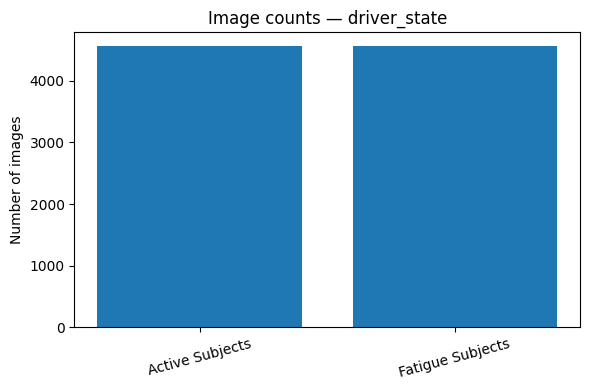

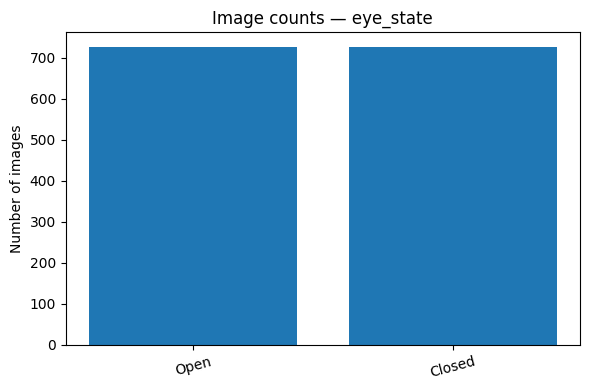

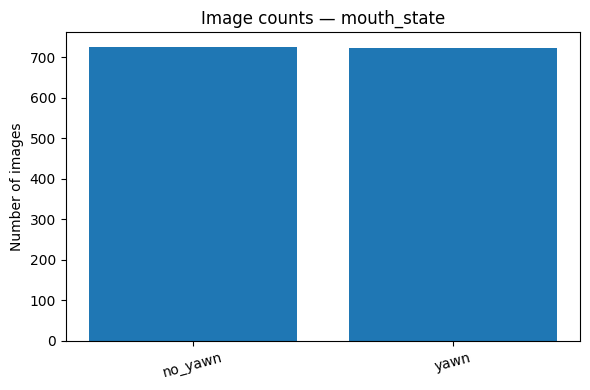

In [4]:
distribution_rows = []
for task_name, class_dict in ALL_FILES.items():
    for class_name, files in class_dict.items():
        distribution_rows.append({
            "task": task_name,
            "class": class_name,
            "images": len(files)
        })

distribution_df = pd.DataFrame(distribution_rows)
display(distribution_df)

for task_name in DATASETS:
    subset = distribution_df[distribution_df["task"] == task_name]
    plt.figure(figsize=(6, 4))
    plt.bar(subset["class"], subset["images"])
    plt.title(f"Image counts — {task_name}")
    plt.ylabel("Number of images")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

## 6. Create train / validation / test splits

The split is stratified by class: 70% training, 15% validation and 15% test. The test set must not be used to choose hyperparameters or thresholds. **If you have person, video or session identifiers, use a group-based split instead.**

In [5]:
SPLITS = {}

def create_splits(task_name, cfg):
    paths, labels = [], []
    for label, class_name in enumerate(cfg["classes"]):
        class_files = ALL_FILES[task_name][class_name]
        paths.extend([str(p) for p in class_files])
        labels.extend([label] * len(class_files))

    paths = np.asarray(paths)
    labels = np.asarray(labels, dtype=np.int32)

    # Split off train set and temporary (validation + test) set.
    x_train, x_temp, y_train, y_temp = train_test_split(
        paths, labels,
        test_size=(1.0 - TRAIN_FRACTION),
        random_state=SEED,
        stratify=labels
    )

    # Split temporary set equally into validation and test.
    test_share_of_temp = TEST_FRACTION / (VALIDATION_FRACTION + TEST_FRACTION)
    x_val, x_test, y_val, y_test = train_test_split(
        x_temp, y_temp,
        test_size=test_share_of_temp,
        random_state=SEED,
        stratify=y_temp
    )

    return {
        "train": (x_train, y_train),
        "validation": (x_val, y_val),
        "test": (x_test, y_test)
    }

for task_name, cfg in DATASETS.items():
    SPLITS[task_name] = create_splits(task_name, cfg)
    print(f"\\n{task_name}")
    for split_name, (x, y) in SPLITS[task_name].items():
        counts = np.bincount(y, minlength=2)
        print(f"{split_name:10s}: {len(x):5d} images | class 0={counts[0]} | class 1={counts[1]}")

\ndriver_state
train     :  6383 images | class 0=3191 | class 1=3192
validation:  1368 images | class 0=684 | class 1=684
test      :  1369 images | class 0=685 | class 1=684
\neye_state
train     :  1016 images | class 0=508 | class 1=508
validation:   218 images | class 0=109 | class 1=109
test      :   218 images | class 0=109 | class 1=109
\nmouth_state
train     :  1013 images | class 0=507 | class 1=506
validation:   217 images | class 0=109 | class 1=108
test      :   218 images | class 0=109 | class 1=109


## 7. Display sample images

Inspect these samples manually. Check that images match their folder labels, that the relevant region is visible, and that there are no obvious corrupt files.

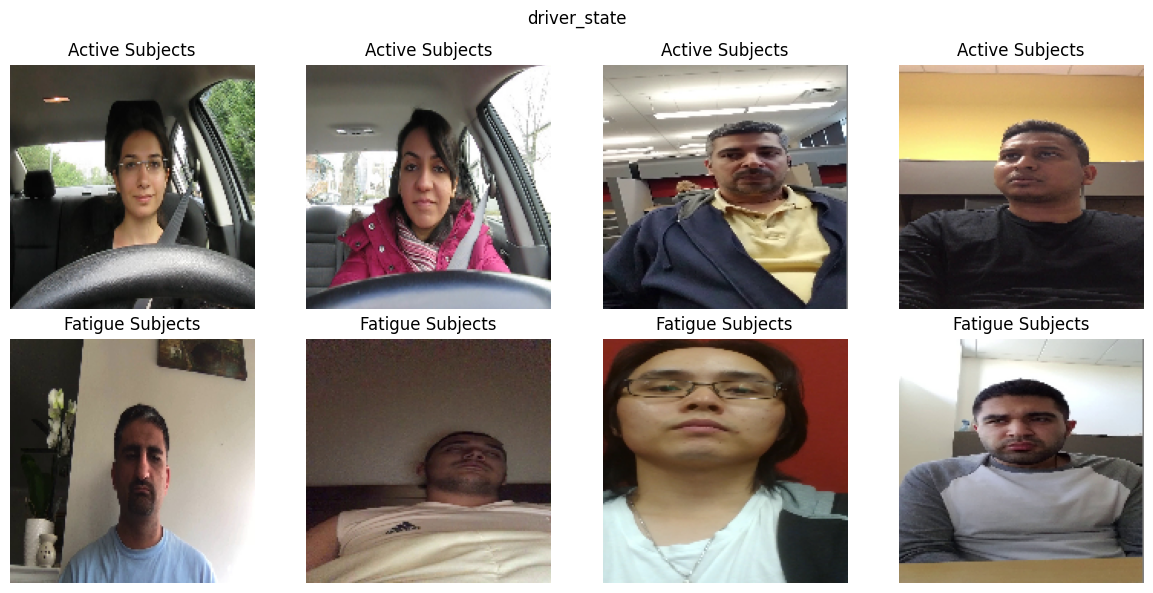

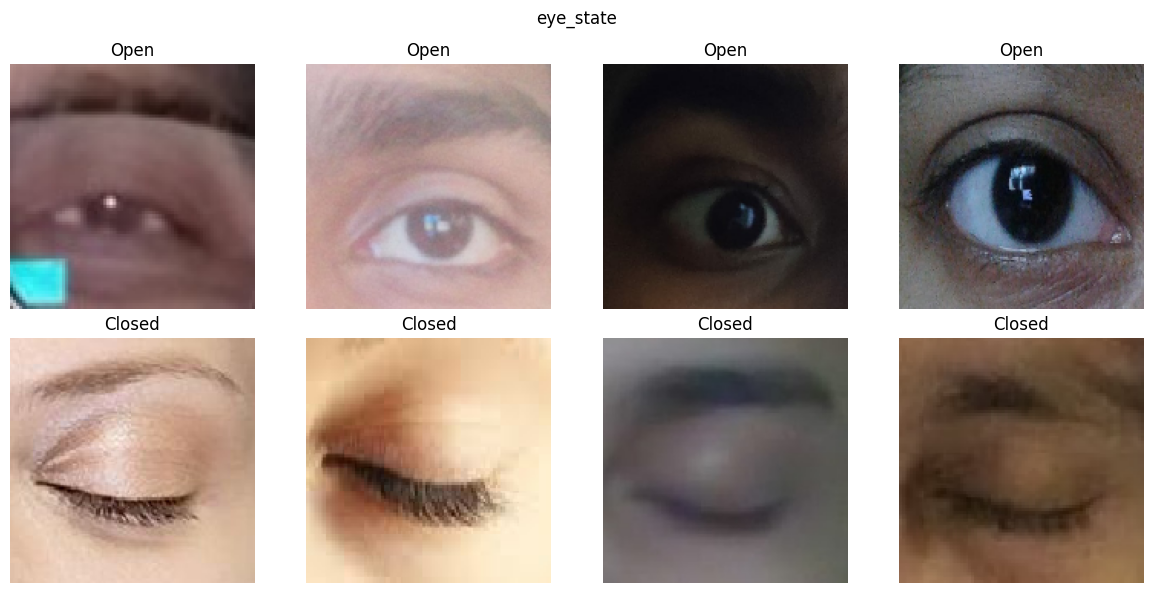

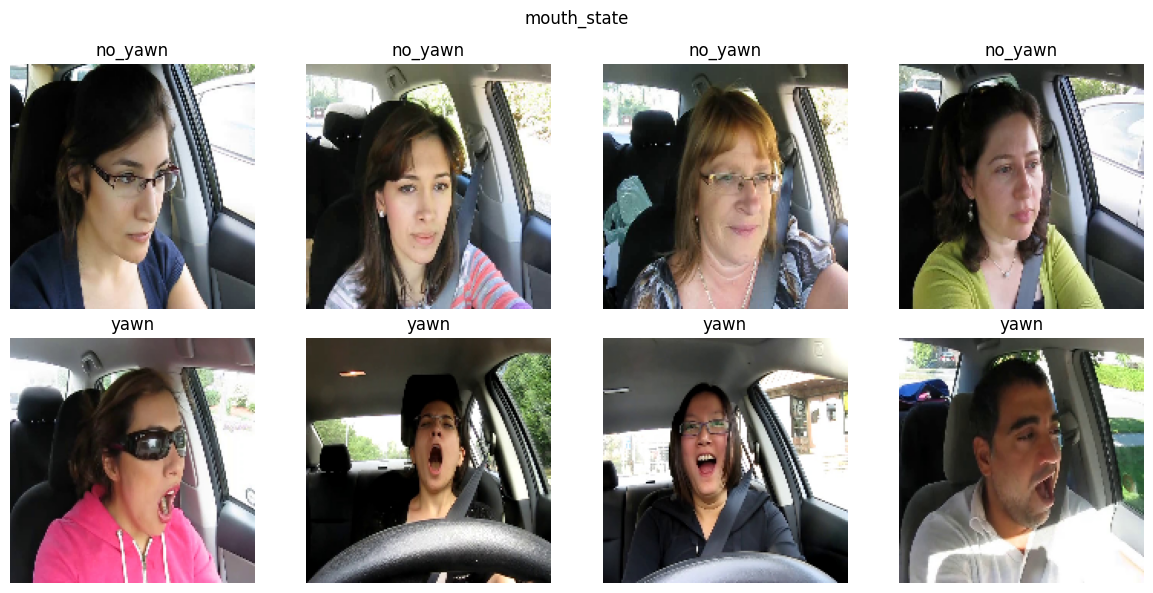

In [6]:
def display_samples(task_name, samples_per_class=4):
    classes = DATASETS[task_name]["classes"]
    fig, axes = plt.subplots(2, samples_per_class, figsize=(3*samples_per_class, 6))
    axes = np.array(axes).reshape(2, samples_per_class)

    for row, class_name in enumerate(classes):
        files = ALL_FILES[task_name][class_name]
        selected = random.sample(files, min(samples_per_class, len(files)))
        for col, ax in enumerate(axes[row]):
            ax.axis("off")
            if col < len(selected):
                img = tf.keras.utils.load_img(selected[col], target_size=IMAGE_SIZE)
                ax.imshow(img)
                ax.set_title(class_name)

    plt.suptitle(task_name)
    plt.tight_layout()
    plt.show()

for task_name in DATASETS:
    display_samples(task_name)

## 8. Build TensorFlow input pipelines

Images are decoded as RGB and resized to 160×160. Pixel values remain in the 0–255 range here. MobileNetV2 preprocessing is included inside the model, so do not preprocess the images a second time.

In [7]:
def decode_and_resize(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32)  # 0..255
    label = tf.cast(label, tf.float32)
    return image, label

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )
    ds = ds.map(decode_and_resize, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)
    return ds

TF_DATASETS = {}
for task_name, split_dict in SPLITS.items():
    TF_DATASETS[task_name] = {
        "train": make_dataset(*split_dict["train"], training=True),
        "validation": make_dataset(*split_dict["validation"], training=False),
        "test": make_dataset(*split_dict["test"], training=False),
    }

for task_name in DATASETS:
    xb, yb = next(iter(TF_DATASETS[task_name]["train"]))
    print(task_name, "image batch:", xb.shape, "label batch:", yb.shape,
          "| pixel range:", float(tf.reduce_min(xb)), "to", float(tf.reduce_max(xb)))

driver_state image batch: (32, 160, 160, 3) label batch: (32,) | pixel range: 0.0 to 255.0
eye_state image batch: (32, 160, 160, 3) label batch: (32,) | pixel range: 0.0 to 255.0
mouth_state image batch: (32, 160, 160, 3) label batch: (32,) | pixel range: 0.0 to 255.0


## 9. Create a consistent data interface and class weights

`DATA` contains both DataFrames (for counts and inspecting errors) and TensorFlow datasets (for model training). `TASKS` stores class names and label meaning.

In [8]:
TASKS = {
    task_name: {
        "class_names": cfg["classes"],
        "positive_class": cfg["positive_class"]
    }
    for task_name, cfg in DATASETS.items()
}

DATA = {}
for task_name in DATASETS:
    train_paths, train_labels = SPLITS[task_name]["train"]
    val_paths, val_labels = SPLITS[task_name]["validation"]
    test_paths, test_labels = SPLITS[task_name]["test"]

    DATA[task_name] = {
        "train": pd.DataFrame({"path": train_paths, "label": train_labels}),
        "validation": pd.DataFrame({"path": val_paths, "label": val_labels}),
        "test": pd.DataFrame({"path": test_paths, "label": test_labels}),
        "train_ds": TF_DATASETS[task_name]["train"],
        "val_ds": TF_DATASETS[task_name]["validation"],
        "test_ds": TF_DATASETS[task_name]["test"],
    }

def calculate_class_weights(train_df):
    counts = train_df["label"].value_counts().reindex([0, 1], fill_value=0)
    if (counts == 0).any():
        raise ValueError("Both classes must have training images.")
    total = counts.sum()
    return {
        int(class_id): float(total / (2 * count))
        for class_id, count in counts.items()
    }

CLASS_WEIGHTS = {}
for task_name in TASKS:
    CLASS_WEIGHTS[task_name] = calculate_class_weights(DATA[task_name]["train"])
    print(task_name, "class weights:", CLASS_WEIGHTS[task_name])

driver_state class weights: {0: 1.000156690692573, 1: 0.9998433583959899}
eye_state class weights: {0: 1.0, 1: 1.0}
mouth_state class weights: {0: 0.9990138067061144, 1: 1.0009881422924902}


## 10. Define data augmentation and MobileNetV2 model

Augmentation is active only during training. MobileNetV2 is initialized with ImageNet weights and its own `preprocess_input` operation is included inside the model. The final sigmoid output is the score for class 1 (the positive class).

In [9]:
def build_binary_model():
    inputs = tf.keras.Input(shape=(*IMAGE_SIZE, 3), name="image")

    augmentation = tf.keras.Sequential([
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.05),
        tf.keras.layers.RandomZoom(0.10),
        tf.keras.layers.RandomContrast(0.10),
    ], name="data_augmentation")

    x = augmentation(inputs)
    x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

    backbone = tf.keras.applications.MobileNetV2(
        input_shape=(*IMAGE_SIZE, 3),
        include_top=False,
        weights="imagenet"
    )
    backbone.trainable = False

    x = backbone(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.30)(x)
    x = tf.keras.layers.Dense(128, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.25)(x)
    outputs = tf.keras.layers.Dense(
        1, activation="sigmoid", name="positive_class_score"
    )(x)

    model = tf.keras.Model(inputs, outputs, name="mobilenetv2_binary_classifier")
    return model, backbone

# Build one model and inspect its architecture before training.
_preview_model, _preview_backbone = build_binary_model()
_preview_model.summary()
del _preview_model, _preview_backbone

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_binary_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ positive_class_score (Dense)    │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 11. Train one task in two stages

**Stage 1:** freeze MobileNetV2 and train the new classification head. **Stage 2:** unfreeze the last selected backbone layers and fine-tune using a smaller learning rate. BatchNormalization layers remain frozen for more stable fine-tuning on smaller datasets.

In [10]:
def compile_model(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.AUC(name="auc")
        ]
    )

def make_callbacks(task_name, stage_name):
    checkpoint_path = OUTPUT_DIR / f"{task_name}_best.keras"
    return [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_loss",
            save_best_only=True,
            verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True,
            verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.3,
            patience=2,
            min_lr=1e-7,
            verbose=1
        )
    ]

def train_one_task(task_name):
    print("\\n" + "="*70)
    print("TRAINING:", task_name)
    print("="*70)

    task_data = DATA[task_name]
    model, backbone = build_binary_model()
    checkpoint_path = OUTPUT_DIR / f"{task_name}_best.keras"

    # Stage 1: train the classification head.
    compile_model(model, HEAD_LEARNING_RATE)
    print("\\nSTAGE 1 — frozen MobileNetV2 backbone")
    history_head = model.fit(
        task_data["train_ds"],
        validation_data=task_data["val_ds"],
        epochs=HEAD_EPOCHS,
        class_weight=CLASS_WEIGHTS[task_name],
        callbacks=make_callbacks(task_name, "head"),
        verbose=1
    )

    # Stage 2: fine-tune the last layers.
    print("\\nSTAGE 2 — fine-tuning")
    backbone.trainable = True
    for layer in backbone.layers[:-UNFREEZE_LAST_LAYERS]:
        layer.trainable = False
    for layer in backbone.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False

    compile_model(model, FINE_TUNE_LEARNING_RATE)
    history_fine = model.fit(
        task_data["train_ds"],
        validation_data=task_data["val_ds"],
        epochs=FINE_TUNE_EPOCHS,
        class_weight=CLASS_WEIGHTS[task_name],
        callbacks=make_callbacks(task_name, "fine_tune"),
        verbose=1
    )

    # Reload the best checkpoint according to validation loss.
    best_model = tf.keras.models.load_model(checkpoint_path)
    return best_model, history_head, history_fine

MODELS = {}
HISTORIES = {}

for task_name in TASKS:
    model, hist_head, hist_fine = train_one_task(task_name)
    MODELS[task_name] = model
    HISTORIES[task_name] = {
        "head": hist_head,
        "fine_tune": hist_fine
    }

print("\\nTraining finished for all three tasks.")

\n======================================================================
TRAINING: driver_state
\nSTAGE 1 — frozen MobileNetV2 backbone
Epoch 1/12
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 557ms/step - accuracy: 0.7383 - auc: 0.8276 - loss: 0.5162 - precision: 0.7328 - recall: 0.7466
Epoch 1: val_loss improved from None to 0.39564, saving model to /kaggle/working/driver_detection_models/driver_state_best.keras

Epoch 1: finished saving model to /kaggle/working/driver_detection_models/driver_state_best.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 151s 697ms/step - accuracy: 0.7702 - auc: 0.8663 - loss: 0.4550 - precision: 0.7665 - recall: 0.7773 - val_accuracy: 0.8099 - val_auc: 0.9033 - val_loss: 0.3956 - val_precision: 0.7912 - val_recall: 0.8421 - learning_rate: 0.0010
Epoch 2/12
199/200 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.7964 - auc: 0.8970 - loss: 0.3944 - precision: 0.7902 - recall: 0.8077
Epoch 2: val_loss improved from 0.39564 to 0.38967, saving model to /kaggle/working/driver_detection

## 12. Plot training curves

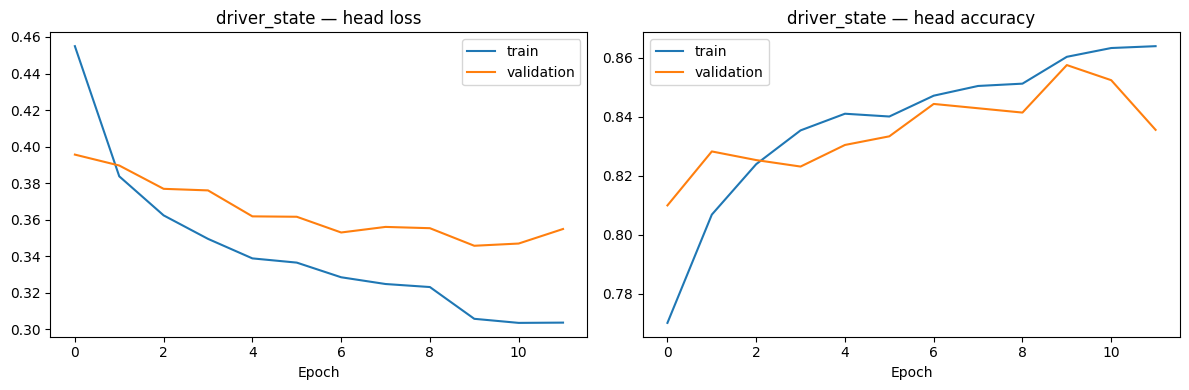

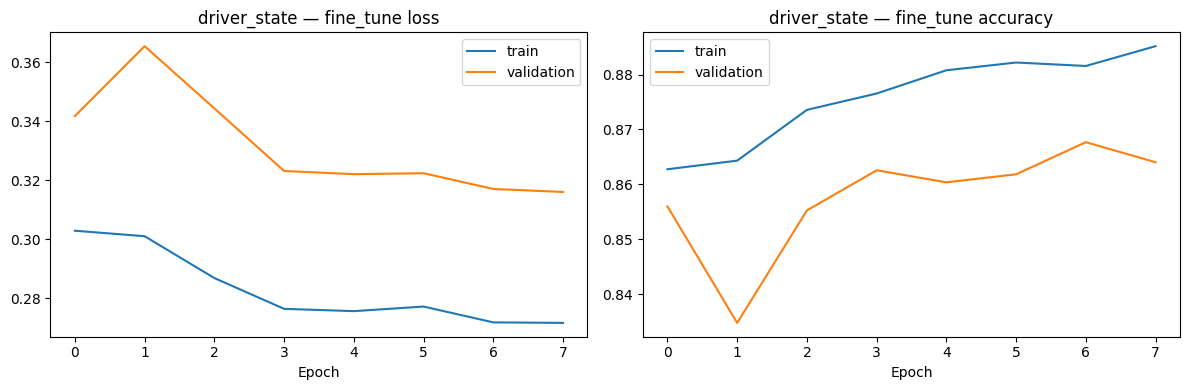

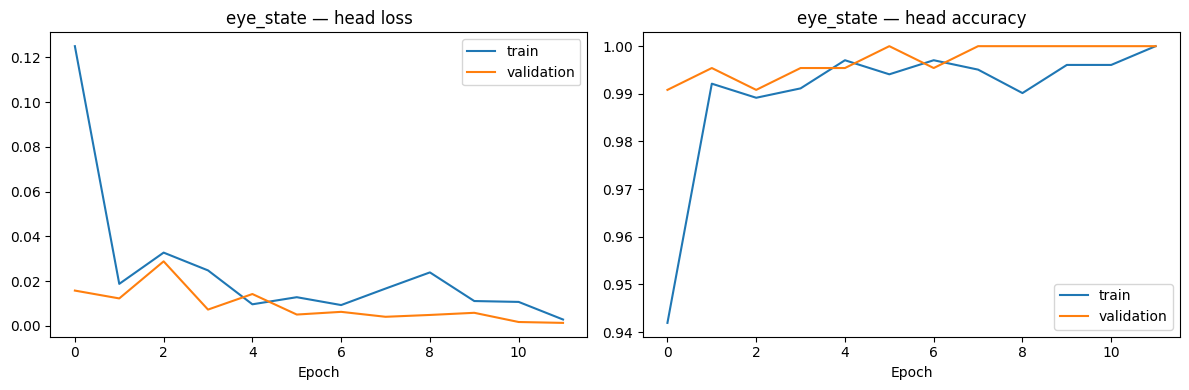

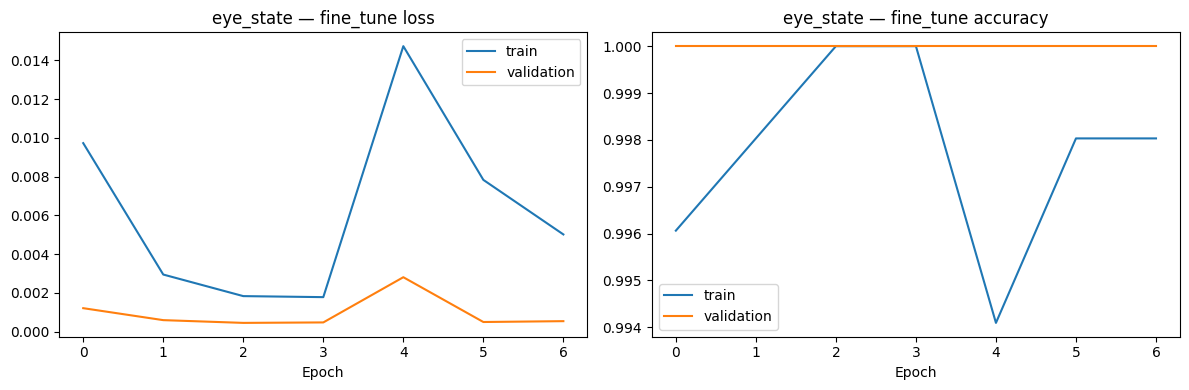

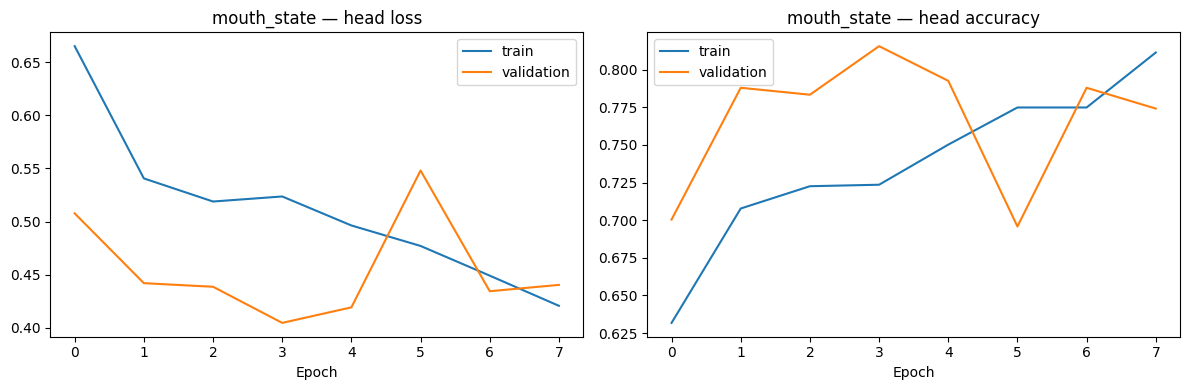

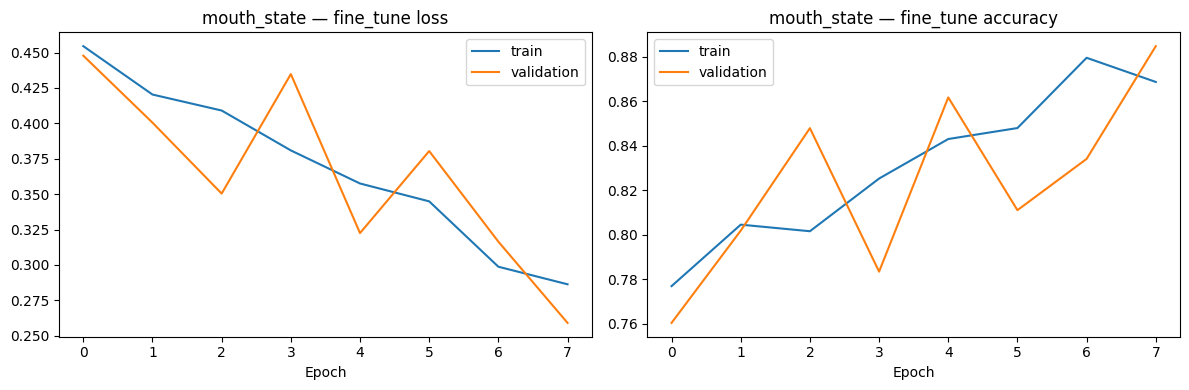

In [11]:
def plot_history(history, task_name, stage_name):
    hist = history.history
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(hist.get("loss", []), label="train")
    plt.plot(hist.get("val_loss", []), label="validation")
    plt.title(f"{task_name} — {stage_name} loss")
    plt.xlabel("Epoch")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(hist.get("accuracy", []), label="train")
    plt.plot(hist.get("val_accuracy", []), label="validation")
    plt.title(f"{task_name} — {stage_name} accuracy")
    plt.xlabel("Epoch")
    plt.legend()

    plt.tight_layout()
    plt.show()

for task_name, stages in HISTORIES.items():
    for stage_name, history in stages.items():
        plot_history(history, task_name, stage_name)

## 13. Evaluation helpers

The positive class is label 1. Precision answers: of the images predicted positive, how many were positive? Recall answers: of all actual positive images, how many were found? F1 balances precision and recall. ROC-AUC measures ranking ability across thresholds.

In [12]:
def collect_predictions(model, dataset):
    y_true, y_score = [], []
    for images, labels in dataset:
        scores = model.predict(images, verbose=0).reshape(-1)
        y_score.extend(scores.tolist())
        y_true.extend(labels.numpy().astype(int).tolist())
    return np.asarray(y_true), np.asarray(y_score)

def evaluate_task(task_name, threshold=0.5, dataset_key="test_ds"):
    model = MODELS[task_name]
    dataset = DATA[task_name][dataset_key]
    class_names = TASKS[task_name]["class_names"]

    y_true, y_score = collect_predictions(model, dataset)
    y_pred = (y_score >= threshold).astype(int)

    print(f"\\n===== {task_name} | threshold={threshold:.3f} =====")
    print(classification_report(
        y_true, y_pred, target_names=class_names, zero_division=0
    ))

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    display_cm = ConfusionMatrixDisplay(cm, display_labels=class_names)
    display_cm.plot(cmap="Blues", values_format="d")
    plt.title(task_name)
    plt.tight_layout()
    plt.show()

    try:
        auc = roc_auc_score(y_true, y_score)
        print("ROC-AUC:", round(float(auc), 4))
    except ValueError:
        auc = None
        print("ROC-AUC unavailable: only one class is present.")

    return {
        "y_true": y_true,
        "y_score": y_score,
        "y_pred": y_pred,
        "auc": auc
    }

## 14. Baseline test evaluation at threshold 0.50

This gives a baseline report. The final threshold-adjusted test report is produced in Section 16 after thresholds are selected using validation data.

\n===== driver_state | threshold=0.500 =====
                  precision    recall  f1-score   support

 Active Subjects       0.89      0.84      0.86       685
Fatigue Subjects       0.85      0.90      0.87       684

        accuracy                           0.87      1369
       macro avg       0.87      0.87      0.87      1369
    weighted avg       0.87      0.87      0.87      1369



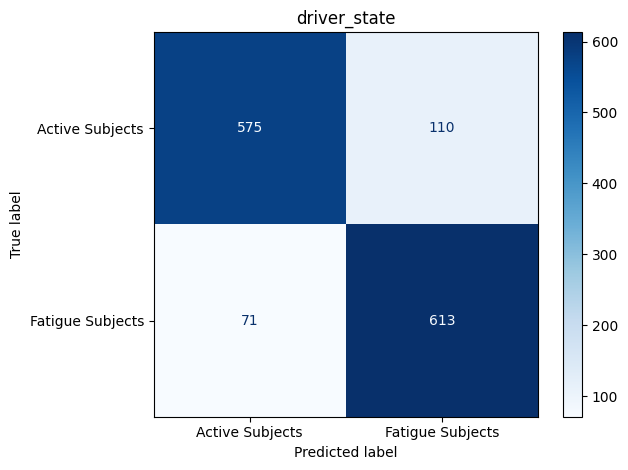

ROC-AUC: 0.9506
\n===== eye_state | threshold=0.500 =====
              precision    recall  f1-score   support

        Open       1.00      0.99      1.00       109
      Closed       0.99      1.00      1.00       109

    accuracy                           1.00       218
   macro avg       1.00      1.00      1.00       218
weighted avg       1.00      1.00      1.00       218



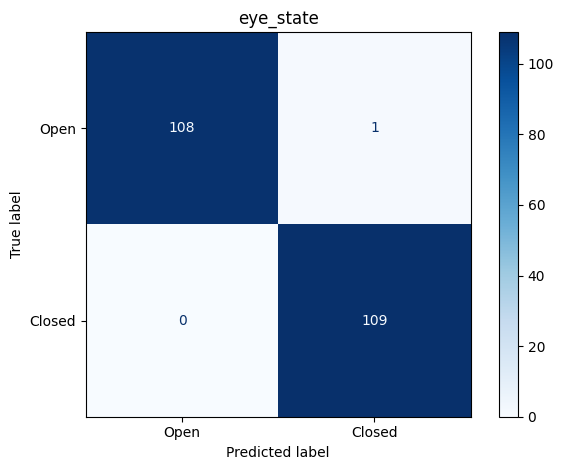

ROC-AUC: 1.0
\n===== mouth_state | threshold=0.500 =====
              precision    recall  f1-score   support

     no_yawn       0.84      0.99      0.91       109
        yawn       0.99      0.81      0.89       109

    accuracy                           0.90       218
   macro avg       0.91      0.90      0.90       218
weighted avg       0.91      0.90      0.90       218



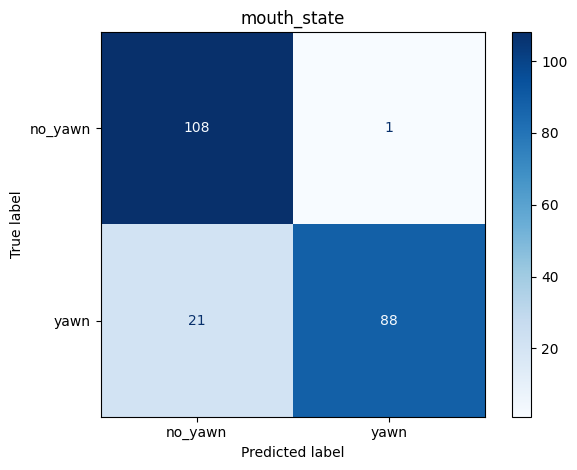

ROC-AUC: 0.9685


In [13]:
TEST_RESULTS = {}
for task_name in TASKS:
    TEST_RESULTS[task_name] = evaluate_task(task_name, threshold=0.50)

## 15. Select thresholds using validation data only

A threshold of 0.5 is only a default. This section selects the threshold that maximizes positive-class F1 on the validation set. Do not select thresholds using test results.

In [14]:
def find_validation_threshold(task_name):
    model = MODELS[task_name]
    y_true, y_score = collect_predictions(model, DATA[task_name]["val_ds"])

    thresholds = np.linspace(0.10, 0.90, 81)
    rows = []
    for threshold in thresholds:
        y_pred = (y_score >= threshold).astype(int)
        precision, recall, f1, _ = precision_recall_fscore_support(
            y_true, y_pred, average="binary", zero_division=0
        )
        rows.append((threshold, precision, recall, f1))

    table = pd.DataFrame(
        rows, columns=["threshold", "precision", "recall", "f1"]
    )
    best = table.loc[table["f1"].idxmax()]
    print(f"\\n{task_name}: validation-selected threshold")
    display(best.to_frame("value"))
    return table, float(best["threshold"])

VALIDATION_THRESHOLDS = {}
THRESHOLD_TABLES = {}
for task_name in TASKS:
    table, threshold = find_validation_threshold(task_name)
    THRESHOLD_TABLES[task_name] = table
    VALIDATION_THRESHOLDS[task_name] = threshold

print("Selected validation thresholds:", VALIDATION_THRESHOLDS)

\ndriver_state: validation-selected threshold


,value
threshold,0.450000
precision,0.846260
recall,0.893275
f1,0.869132


\neye_state: validation-selected threshold


,value
threshold,0.1
precision,1.0
recall,1.0
f1,1.0


\nmouth_state: validation-selected threshold


,value
threshold,0.330000
precision,0.909910
recall,0.935185
f1,0.922374


Selected validation thresholds: {'driver_state': 0.45000000000000007, 'eye_state': 0.1, 'mouth_state': 0.33}


## 16. Final test evaluation with selected thresholds

This evaluates the held-out test data using thresholds selected on validation data. Use this final test evaluation for reporting; avoid repeatedly tuning the model based on test results.

\n===== driver_state | threshold=0.450 =====
                  precision    recall  f1-score   support

 Active Subjects       0.90      0.82      0.86       685
Fatigue Subjects       0.83      0.91      0.87       684

        accuracy                           0.86      1369
       macro avg       0.87      0.86      0.86      1369
    weighted avg       0.87      0.86      0.86      1369



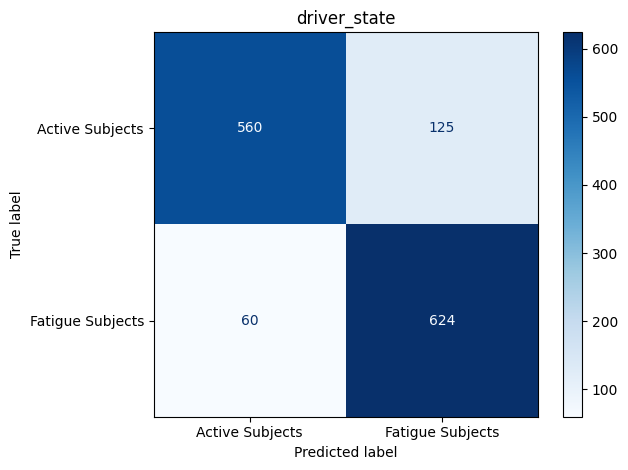

ROC-AUC: 0.9506
\n===== eye_state | threshold=0.100 =====
              precision    recall  f1-score   support

        Open       1.00      0.99      1.00       109
      Closed       0.99      1.00      1.00       109

    accuracy                           1.00       218
   macro avg       1.00      1.00      1.00       218
weighted avg       1.00      1.00      1.00       218



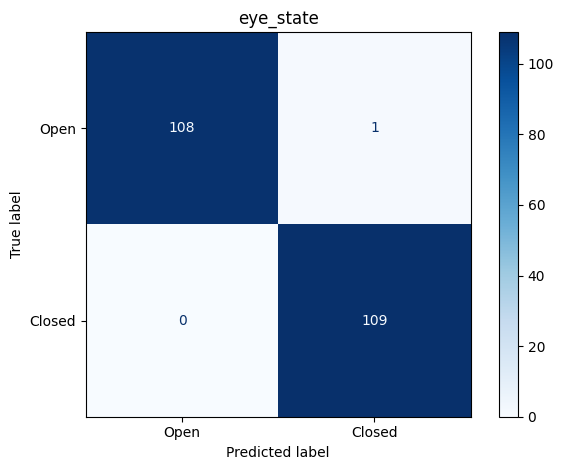

ROC-AUC: 1.0
\n===== mouth_state | threshold=0.330 =====
              precision    recall  f1-score   support

     no_yawn       0.88      0.96      0.92       109
        yawn       0.96      0.86      0.91       109

    accuracy                           0.91       218
   macro avg       0.92      0.91      0.91       218
weighted avg       0.92      0.91      0.91       218



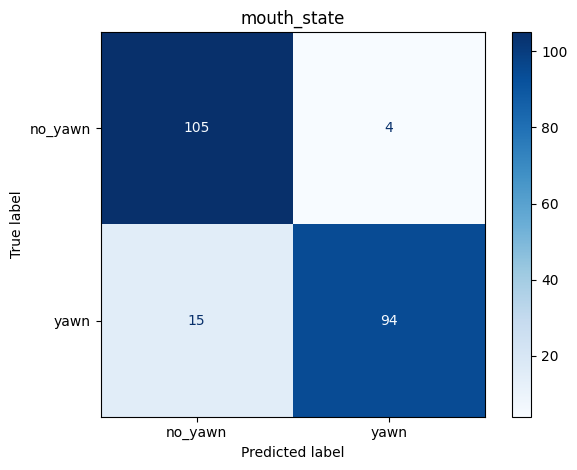

ROC-AUC: 0.9685


In [15]:
FINAL_TEST_RESULTS = {}
for task_name in TASKS:
    FINAL_TEST_RESULTS[task_name] = evaluate_task(
        task_name,
        threshold=VALIDATION_THRESHOLDS[task_name],
        dataset_key="test_ds"
    )

## 17. Inspect misclassified test images

False positives and false negatives can reveal label problems, poor crops, lighting differences, occlusion or insufficient variety.

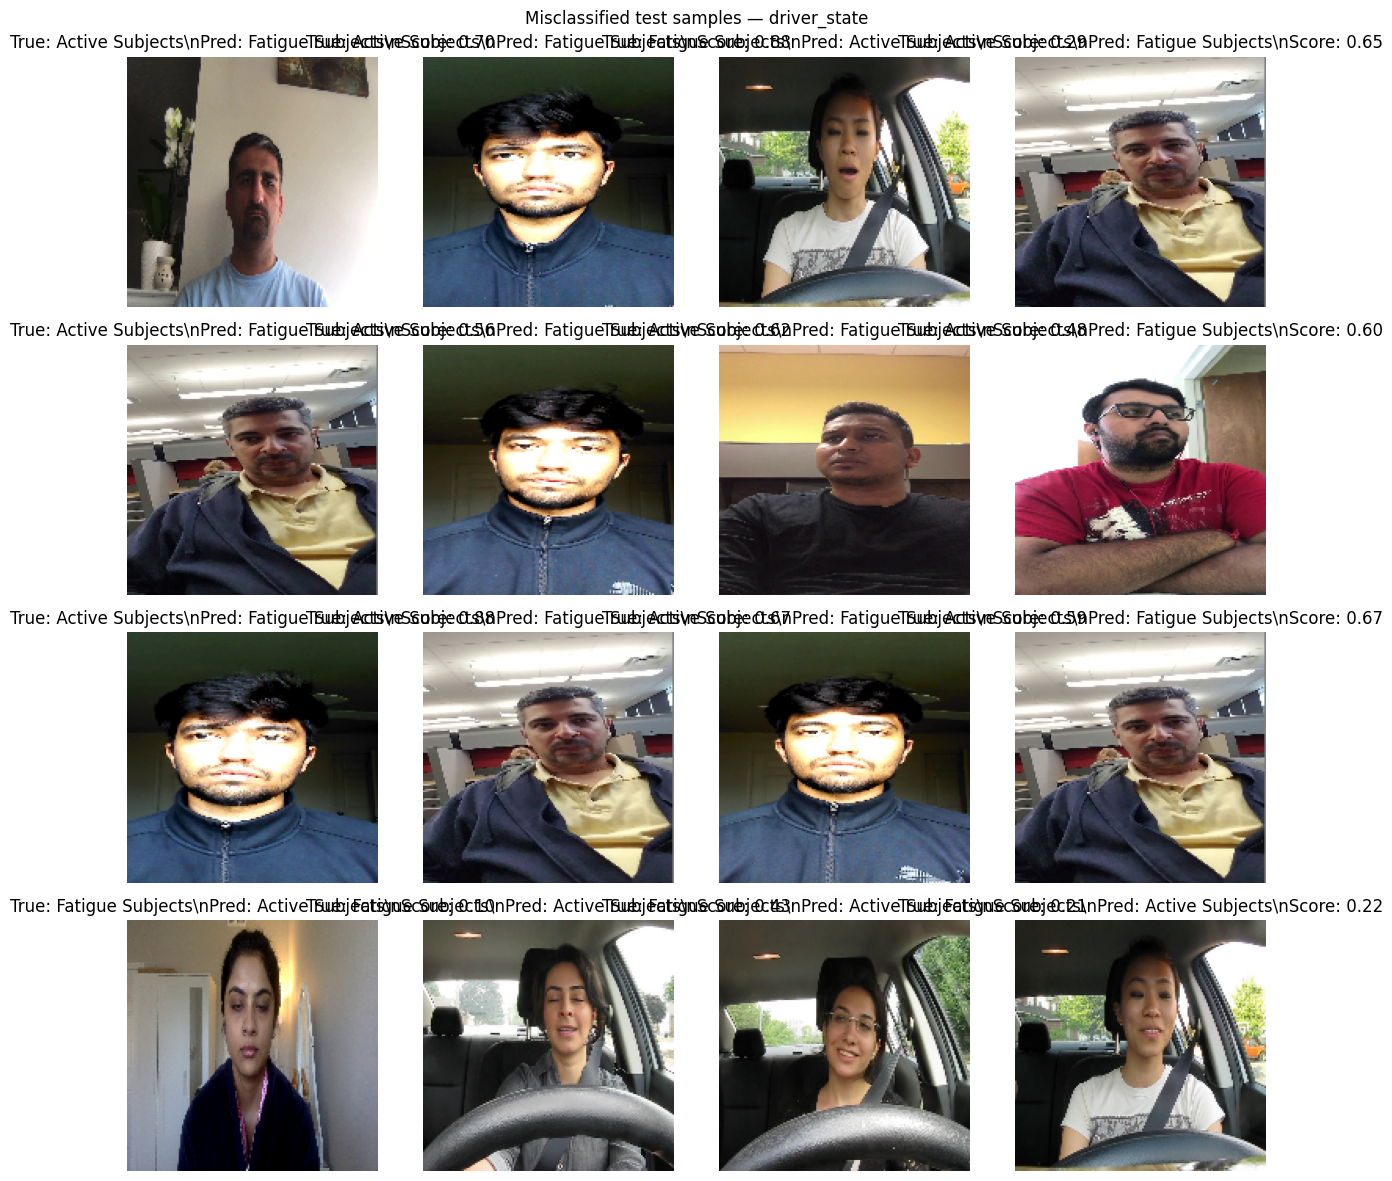

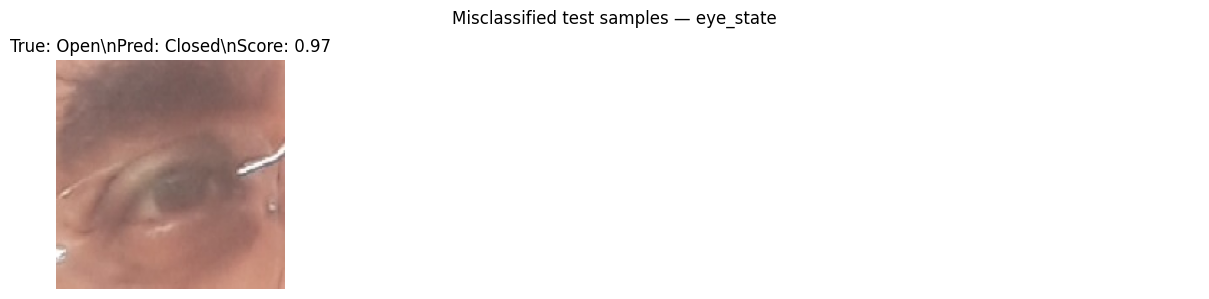

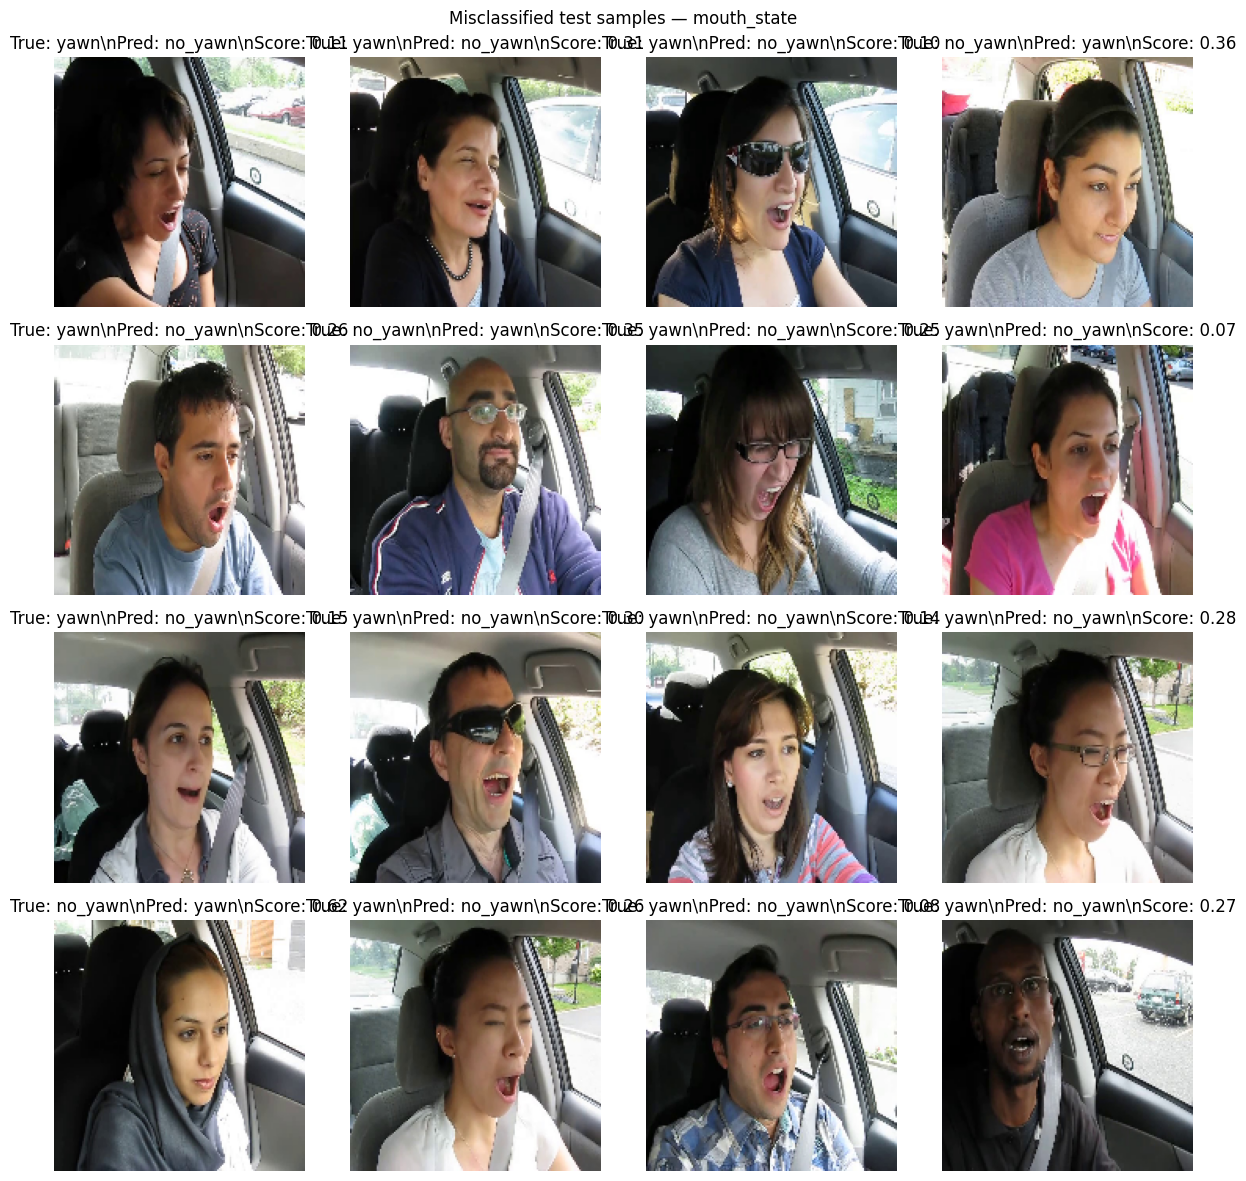

In [16]:
def show_misclassified(task_name, max_images=16):
    result = FINAL_TEST_RESULTS[task_name]
    test_df = DATA[task_name]["test"].reset_index(drop=True)
    wrong_indices = np.where(result["y_true"] != result["y_pred"])[0][:max_images]

    if len(wrong_indices) == 0:
        print(task_name, ": no misclassified samples in this test set.")
        return

    cols = 4
    rows = int(np.ceil(len(wrong_indices) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(12, 3 * rows))
    axes = np.asarray(axes).reshape(-1)
    class_names = TASKS[task_name]["class_names"]

    for ax, idx in zip(axes, wrong_indices):
        row = test_df.iloc[idx]
        image = tf.keras.utils.load_img(row["path"], target_size=IMAGE_SIZE)
        ax.imshow(image)
        true_name = class_names[int(result["y_true"][idx])]
        pred_name = class_names[int(result["y_pred"][idx])]
        score = result["y_score"][idx]
        ax.set_title(f"True: {true_name}\\nPred: {pred_name}\\nScore: {score:.2f}")
        ax.axis("off")

    for ax in axes[len(wrong_indices):]:
        ax.axis("off")

    plt.suptitle(f"Misclassified test samples — {task_name}")
    plt.tight_layout()
    plt.show()

for task_name in TASKS:
    show_misclassified(task_name)

## 18. Save the three models and metadata

Each `.keras` model contains the architecture, weights, augmentation and MobileNetV2 preprocessing. For inference, supply RGB images resized to 160×160 with pixel values in the 0–255 range. Do not apply `preprocess_input` again.

In [17]:
for task_name, model in MODELS.items():
    output_path = OUTPUT_DIR / f"{task_name}_final.keras"
    model.save(output_path)
    print("Saved:", output_path)

metadata = {
    "image_size": list(IMAGE_SIZE),
    "input_color": "RGB",
    "input_pixel_range": [0, 255],
    "preprocessing": "MobileNetV2 preprocess_input is included inside the model",
    "tasks": {
        task_name: {
            "class_names": TASKS[task_name]["class_names"],
            "positive_class": TASKS[task_name]["positive_class"],
            "positive_class_label": 1,
            "model_file": f"{task_name}_final.keras",
            "validation_selected_threshold": VALIDATION_THRESHOLDS[task_name]
        }
        for task_name in TASKS
    },
    "warning": (
        "Educational research prototype; not validated for real-world "
        "driver safety or vehicle control."
    )
}

config_path = OUTPUT_DIR / "inference_config.json"
with open(config_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("\\nExport contents:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(path.name, f"({path.stat().st_size / (1024**2):.2f} MB)")

Saved: /kaggle/working/driver_detection_models/driver_state_final.keras
Saved: /kaggle/working/driver_detection_models/eye_state_final.keras
Saved: /kaggle/working/driver_detection_models/mouth_state_final.keras
\nExport contents:
driver_state_best.keras (22.61 MB)
driver_state_final.keras (22.60 MB)
eye_state_best.keras (22.61 MB)
eye_state_final.keras (22.60 MB)
inference_config.json (0.00 MB)
mouth_state_best.keras (22.61 MB)
mouth_state_final.keras (22.60 MB)


## 19. Load saved models and run one-image inference

Use the correct image type for each model: a face/context image for driver state, an eye crop for eye state, and a mouth crop for mouth state. This example does not perform face detection or crop extraction.

In [18]:
def load_image_for_model(image_path):
    image = tf.keras.utils.load_img(
        image_path,
        color_mode="rgb",
        target_size=IMAGE_SIZE
    )
    array = tf.keras.utils.img_to_array(image).astype("float32")
    return np.expand_dims(array, axis=0)  # batch, RGB, 0..255

def predict_image(model, image_path, class_names, threshold=0.5):
    batch = load_image_for_model(image_path)
    positive_score = float(model.predict(batch, verbose=0)[0, 0])
    predicted_label = int(positive_score >= threshold)
    return {
        "predicted_class": class_names[predicted_label],
        "positive_class_score": positive_score,
        "threshold": threshold
    }

# Example after training:
# result = predict_image(
#     MODELS["eye_state"],
#     "/path/to/an_eye_crop.jpg",
#     TASKS["eye_state"]["class_names"],
#     VALIDATION_THRESHOLDS["eye_state"]
# )
# print(result)

## 20. How to interpret results and improve the project

### High training accuracy, low validation/test accuracy
Possible overfitting, data leakage, duplicates, or a mismatch between training and evaluation images. Add varied subjects/sessions and inspect the split.

### Low training and validation accuracy
Check labels, image quality, crop quality, class definitions and whether the relevant region is visible. More model complexity is not always the answer.

### Low positive-class recall
Inspect false negatives. Improve the diversity and correctness of positive examples. Thresholds can trade precision for recall, but choose them on validation data and report the trade-off.

### Driver-state classifier is weak
Fatigue is not always visually identifiable from a single still image. Temporal signals such as sustained eye closure or repeated yawning may be more meaningful, but require complete recordings and separate validation.

### Reporting checklist
- [ ] Describe dataset sources and class definitions.
- [ ] Report images per class and per split.
- [ ] Document whether split is by image, person, video or session.
- [ ] Check for duplicate and near-duplicate leakage.
- [ ] Report precision, recall, F1 and confusion matrices per class.
- [ ] Choose thresholds on validation data only.
- [ ] Evaluate the test set only after decisions are fixed.
- [ ] Measure model size and inference latency on intended hardware.
- [ ] Explain limitations and that this is not a safety-certified system.

## 21. Troubleshooting

**`FileNotFoundError: Missing folder`** — edit `DATA_ROOT`, each task's `directory`, and the exact class folder names in Section 3. Run the folder-inspection cell below to see your Kaggle directory layout.

**Out-of-memory / GPU memory error** — reduce `BATCH_SIZE` to 16 or 8. If needed, use a smaller image size consistently in the configuration.

**Class weight error** — each class must have enough images to appear in train, validation and test. Add data or adjust the split for very small datasets.

**Model download issue** — MobileNetV2 ImageNet weights need internet access on the first run. Enable internet in the notebook environment or use an available cached weights file.

**Accuracy looks suspiciously high** — investigate whether frames from the same video/person or duplicate images appear in both train and test.

In [19]:
# OPTIONAL: inspect directories under your Kaggle input mount.
# Run this if you are unsure where your dataset folders are.
SEARCH_ROOT = Path("/kaggle/input")
if SEARCH_ROOT.exists():
    for root, dirs, files in os.walk(SEARCH_ROOT):
        level = len(Path(root).relative_to(SEARCH_ROOT).parts)
        if level <= 3:
            image_count = sum(
                1 for name in files
                if Path(name).suffix.lower() in IMAGE_EXTENSIONS
            )
            print("  " * level + Path(root).name + f"/  ({image_count} images)")
        if level >= 3:
            dirs[:] = []

input/  (0 images)
  datasets/  (0 images)
    mohamedamineram/  (0 images)
      fatigedetection2/  (0 images)


## 22. Integration note for a webcam application

This notebook exports **three models**, not one combined model. A real-time pipeline would need to:
1. Detect the driver's face.
2. Extract the face/context image for driver-state classification.
3. Crop the eye region for eye-state classification.
4. Crop the mouth region for mouth-state classification.
5. Resize each input to 160×160 RGB and retain pixel values in 0–255.
6. Run each model and display the three independent estimates.
7. If temporal analysis is added, validate it on independent full recordings.

The notebook does not implement face detection, landmark detection, crop extraction, alarm logic or vehicle control.